In [7]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import torch



# Add the root directory (or src) to sys.path
src_path = str(Path.cwd() / "src")
if src_path not in sys.path:
    sys.path.insert(0, src_path)  # insert(0, ...) prioritizes your code over installed packages

from spring import data



In [8]:
field = data.get_field()
dataset = data.get_dataset()
dataset

{'x': array([[ 0.08047354, -0.06354789],
        [-0.00924063, -0.10803434],
        [ 0.05293825, -0.10030653],
        ...,
        [-0.27739328, -0.86929107],
        [-0.45702229, -0.81420538],
        [-0.64736244, -0.69679708]], shape=(750, 2)),
 'test_x': array([[-0.05078723,  0.55477802],
        [ 0.04318766,  0.5411715 ],
        [ 0.15772386,  0.36006439],
        ...,
        [-0.48493392,  0.04013209],
        [-0.08368154,  0.01431885],
        [-0.2929535 ,  0.09531511]], shape=(750, 2)),
 'dx': array([[-0.23526489, -0.13996706],
        [-0.25900051, -0.08865261],
        [-0.27168761, -0.03355748],
        ...,
        [-1.85678948,  0.66018416],
        [-1.68157253,  1.0275332 ],
        [-1.4346302 ,  1.35105354]], shape=(750, 2)),
 'test_dx': array([[ 1.00840684,  0.1340651 ],
        [ 1.0144411 , -0.07594517],
        [ 0.97720505, -0.2827157 ],
        ...,
        [-0.0133713 ,  0.52193032],
        [ 0.09413114,  0.51354588],
        [ 0.19761749,  0.48325656]

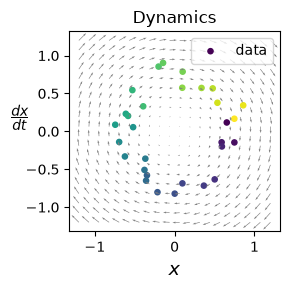

In [9]:

# plot config
fig = plt.figure(figsize=(3, 3), facecolor='white')

x, y, dx, dy, t = data.get_trajectory(radius=0.7, y0=np.array([1,0]))
plt.scatter(x,y,c=t,s=14, label='data')
plt.quiver(field['x'][:,0], field['x'][:,1], field['dx'][:,0], field['dx'][:,1],
           cmap='gray_r', color=(.5,.5,.5))
plt.xlabel("$x$", fontsize=14)
plt.ylabel("$\\frac{dx}{dt}$", rotation=0, fontsize=14)
plt.title("Dynamics")
plt.legend(loc='upper right')

plt.tight_layout() ; plt.show()


In [10]:

device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else "cpu"
print(f"Using {device} device")

Using cuda device


In [23]:
from torch import nn

class BaselineMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.linear_relu_stack = nn.Sequential(
            nn.Linear(2, 512),
            nn.ReLU(),
            nn.Linear(512, 512),
            nn.ReLU(),
            nn.Linear(512, 2),
        )

    def forward(self, x):
        #x = self.flatten(x)
        logits = self.linear_relu_stack(x)
        return logits


model = BaselineMLP()
result = model(torch.tensor(dataset['x'], dtype=torch.float32))
result

tensor([[0.0286, 0.0428],
        [0.0309, 0.0466],
        [0.0299, 0.0452],
        ...,
        [0.0908, 0.0484],
        [0.0973, 0.0516],
        [0.1026, 0.0462]], grad_fn=<AddmmBackward0>)

In [15]:
#print("Input dtype:", inputs.dtype)
print("Model weight dtype:", next(model.parameters()).dtype)

Model weight dtype: torch.float32


In [22]:
model.parameters()

<generator object Module.parameters at 0x000001A72C02A020>

In [27]:
labels = torch.tensor(dataset['dx'], dtype=torch.float32)
loss = result - labels
loss.sum()

tensor(63.2865, grad_fn=<SumBackward0>)

In [28]:
optim = torch.optim.SGD(model.parameters(), lr=1e-2, momentum=0.9)
optim.step()

In [29]:
criterion = nn.MSELoss()
loss = criterion(result, labels)
loss

tensor(0.8804, grad_fn=<MseLossBackward0>)

In [36]:
print("before")
print(model.linear_relu_stack._modules['0'].bias.grad)
loss.backward()
print("after")
print(model.linear_relu_stack._modules['0'].bias.grad)

before
None
after
tensor([ 1.3141e-03, -4.2610e-04,  2.7369e-04,  1.3415e-03, -3.9096e-04,
        -1.3639e-03, -9.1188e-05,  0.0000e+00, -5.6129e-05, -2.9356e-03,
         1.2837e-03, -9.7428e-04, -1.2174e-03,  3.9994e-05, -1.6951e-03,
        -1.3876e-03, -2.6630e-03, -5.2452e-04,  2.1983e-04, -7.8074e-03,
         1.5779e-03,  4.3159e-03, -6.4673e-05, -1.1984e-03,  0.0000e+00,
         6.0117e-03,  0.0000e+00, -9.8827e-04, -3.7497e-03,  4.0829e-03,
         1.1802e-03, -1.3914e-03, -2.8110e-04,  2.5726e-03,  5.9897e-03,
         8.1416e-04,  4.6711e-05,  1.0523e-04, -9.4697e-04, -1.3848e-03,
         4.9969e-03, -8.6389e-04, -1.5966e-03, -2.1878e-03,  3.7590e-04,
        -1.3171e-04, -1.9136e-04, -5.0301e-03,  2.0311e-03, -1.5724e-03,
        -2.3400e-03,  3.3820e-03,  1.7593e-03, -6.0249e-03,  5.1472e-04,
         2.5644e-04,  0.0000e+00,  0.0000e+00, -4.0070e-03,  1.0584e-03,
         0.0000e+00,  5.6387e-03,  0.0000e+00,  2.6853e-03,  6.8824e-03,
        -2.0316e-03, -6.1732e-03,

In [43]:
from torch.utils.data import DataLoader, TensorDataset

train_dataset = TensorDataset(
    torch.tensor(dataset['x'], dtype=torch.float32),
    torch.tensor(dataset['dx'], dtype=torch.float32))

test_dataset = TensorDataset(
    torch.tensor(dataset['test_x'], dtype=torch.float32),
    torch.tensor(dataset['test_dx'], dtype=torch.float32))

train_dataloader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_dataloader = DataLoader(test_dataset, batch_size=32, shuffle=False)



In [51]:
EPOCHS = 200
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = BaselineMLP().to(DEVICE)

criterion = nn.MSELoss()
optim = torch.optim.SGD(model.parameters(), lr=1e-03, momentum=0.9)
for e in range(EPOCHS):
    model.train()
    running_loss = 0.0

    for inputs, labels in train_dataloader:
        inputs = inputs.to(DEVICE)
        labels = labels.to(DEVICE)

        predictions = model(inputs)
        loss = criterion(predictions, labels)

        optim.zero_grad()
        loss.backward()
        optim.step()

        running_loss += loss.item() * inputs.size(0)

    epoch_loss = running_loss / len(train_dataloader.dataset)

    if (e + 1) % 10 == 0 or e == 0:
        print(f'epoch [{e+1}/{EPOCHS} - Loss: {epoch_loss:.6f}')


epoch [1/200 - Loss: 0.664832
epoch [10/200 - Loss: 0.035818
epoch [20/200 - Loss: 0.035379
epoch [30/200 - Loss: 0.035260
epoch [40/200 - Loss: 0.035426
epoch [50/200 - Loss: 0.034814
epoch [60/200 - Loss: 0.034696
epoch [70/200 - Loss: 0.034700
epoch [80/200 - Loss: 0.034541
epoch [90/200 - Loss: 0.034602
epoch [100/200 - Loss: 0.034420
epoch [110/200 - Loss: 0.034442
epoch [120/200 - Loss: 0.034603
epoch [130/200 - Loss: 0.034374
epoch [140/200 - Loss: 0.034320
epoch [150/200 - Loss: 0.034270
epoch [160/200 - Loss: 0.034253
epoch [170/200 - Loss: 0.034177
epoch [180/200 - Loss: 0.034169
epoch [190/200 - Loss: 0.034112
epoch [200/200 - Loss: 0.034026


In [54]:
def get_vector_field(model, **kwargs):
    field = data.get_field(**kwargs)
    np_mesh_x = field['x']
    
    # run model
    mesh_x = torch.tensor( np_mesh_x, requires_grad=True, dtype=torch.float32)
    mesh_dx = model.time_derivative(mesh_x)
    return mesh_dx.data.numpy()

In [68]:
from scipy.integrate import solve_ivp

def integrate_model(model, t_span, y0, **kwargs):
    
    def fun(t, np_x):
        x = torch.tensor( np_x, requires_grad=True, dtype=torch.float32).view(1,2).to(DEVICE)
        dx = model(x).detach().cpu().numpy().reshape(-1)
        return dx

    return solve_ivp(fun=fun, t_span=t_span, y0=y0, **kwargs)

In [76]:
#base_field = get_vector_field(model, gridsize=10)
field = data.get_field()
np_mesh_x = field['x']
mesh_x = torch.tensor(np_mesh_x, requires_grad=True, dtype=torch.float32).to(DEVICE)
base_field = mesh_dx = model(mesh_x).detach().cpu()


In [69]:
# integrate along those fields starting from point (1,0)
t_span = [0,30]
y0 = np.asarray([1., 0])
kwargs = {'t_eval': np.linspace(t_span[0], t_span[1], 2000), 'rtol': 1e-12}
base_ivp = integrate_model(model, t_span, y0, **kwargs)
#hnn_ivp = integrate_model(hnn_model, t_span, y0, **kwargs)

In [70]:
base_ivp

  message: The solver successfully reached the end of the integration interval.
  success: True
   status: 0
        t: [ 0.000e+00  1.501e-02 ...  2.998e+01  3.000e+01]
        y: [[ 1.000e+00  9.990e-01 ...  6.155e-01  6.309e-01]
            [ 0.000e+00 -2.690e-02 ...  5.579e-01  5.401e-01]]
      sol: None
 t_events: None
 y_events: None
     nfev: 2312
     njev: 0
      nlu: 0

Text(0.5, 1.0, 'Baseline NN')

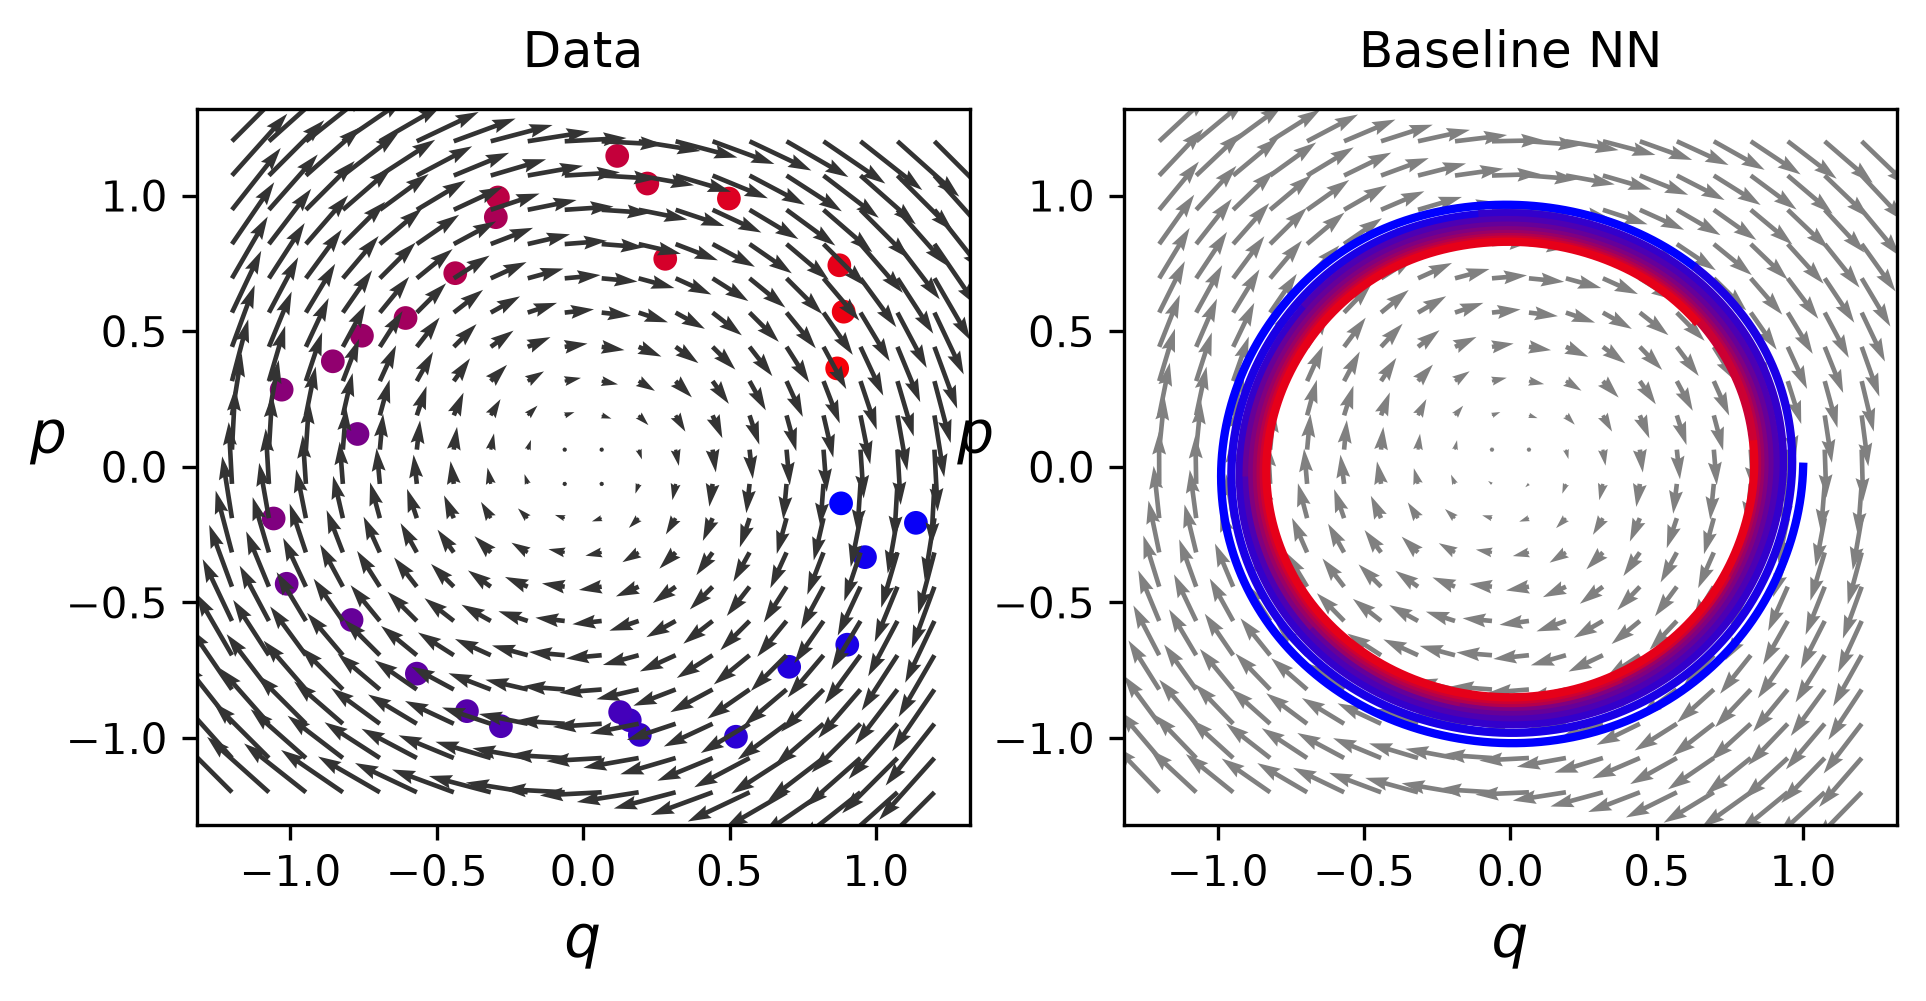

In [77]:

DPI = 300
FORMAT = 'pdf'
LINE_SEGMENTS = 10
ARROW_SCALE = 30
ARROW_WIDTH = 6e-3
LINE_WIDTH = 2
RK4 = ''


fig = plt.figure(figsize=(11.3, 3.1), facecolor='white', dpi=300)

fig.add_subplot(1, 3, 1, frameon=True)
x, y, dx, dy, t = data.get_trajectory(radius=1, y0=np.array([1,0]))
N = len(x)
point_colors = [(i/N, 0, 1-i/N) for i in range(N)]
plt.scatter(x,y, s=22, label='data', c=point_colors)

plt.quiver(field['x'][:,0], field['x'][:,1], field['dx'][:,0], field['dx'][:,1],
        cmap='gray_r', scale=ARROW_SCALE, width=ARROW_WIDTH, color=(.2,.2,.2))  
plt.xlabel("$q$", fontsize=14)
plt.ylabel("$p$", rotation=0, fontsize=14)
plt.title("Data", pad=10)

fig.add_subplot(1, 3, 2, frameon=True)
plt.quiver(field['x'][:,0], field['x'][:,1], base_field[:,0], base_field[:,1],
        cmap='gray_r', scale=ARROW_SCALE, width=ARROW_WIDTH, color=(.5,.5,.5))

for i, l in enumerate(np.split(base_ivp['y'].T, LINE_SEGMENTS)):
    color = (float(i)/LINE_SEGMENTS, 0, 1-float(i)/LINE_SEGMENTS)
    plt.plot(l[:,0],l[:,1],color=color, linewidth=LINE_WIDTH)
    
plt.xlabel("$q$", fontsize=14)
plt.ylabel("$p$", rotation=0, fontsize=14)
plt.title("Baseline NN", pad=10)



In [83]:
untrained_model = BaselineMLP().to(DEVICE)

field = data.get_field()
np_mesh_x = field['x']
mesh_x = torch.tensor(np_mesh_x, requires_grad=True, dtype=torch.float32).to(DEVICE)
base_field = mesh_dx = untrained_model(mesh_x).detach().cpu()

t_span = [0,30]
y0 = np.asarray([1., 0])
kwargs = {'t_eval': np.linspace(t_span[0], t_span[1], 2000), 'rtol': 1e-12}
base_ivp = integrate_model(untrained_model, t_span, y0, **kwargs)


Text(0.5, 1.0, 'Baseline NN')

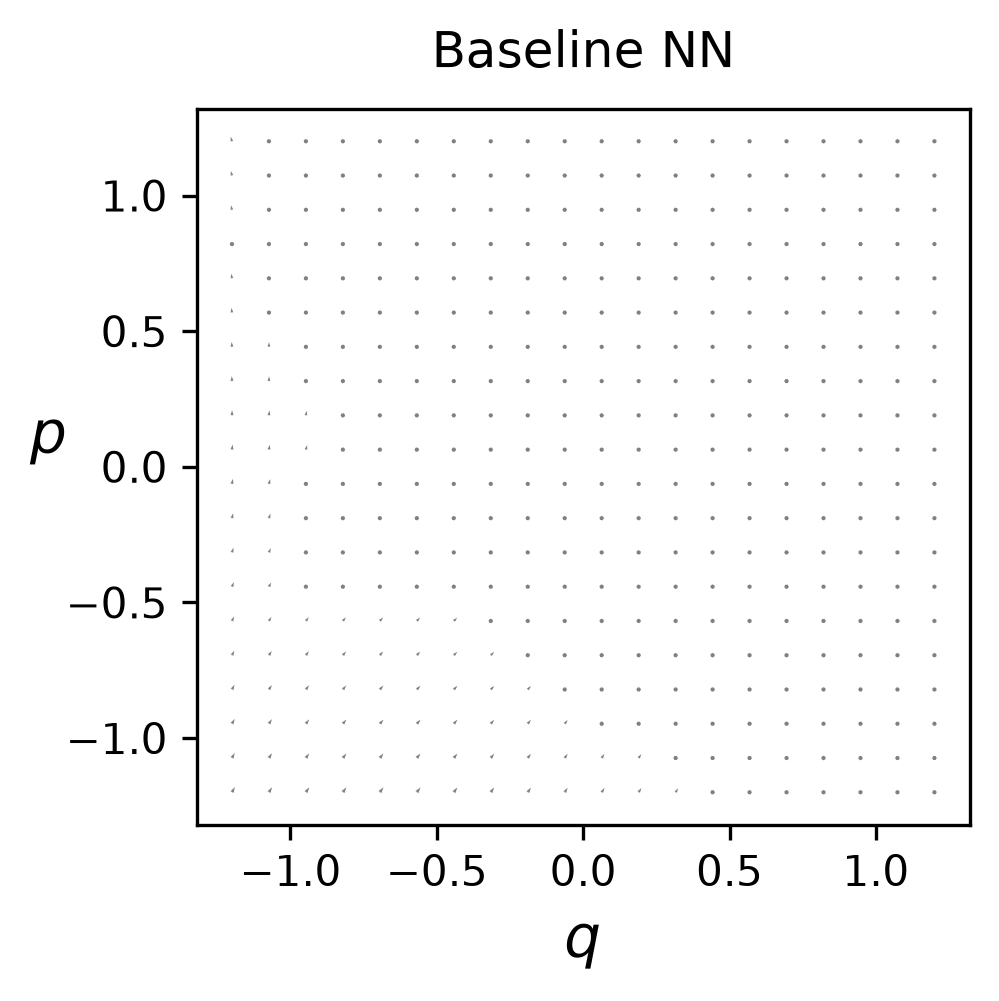

In [85]:
fig = plt.figure(figsize=(11.3, 3.1), facecolor='white', dpi=300)

fig.add_subplot(1, 3, 2, frameon=True)
plt.quiver(field['x'][:,0], field['x'][:,1], base_field[:,0], base_field[:,1],
        cmap='gray_r', scale=ARROW_SCALE, width=ARROW_WIDTH, color=(.5,.5,.5))

# for i, l in enumerate(np.split(base_ivp['y'].T, LINE_SEGMENTS)):
#     color = (float(i)/LINE_SEGMENTS, 0, 1-float(i)/LINE_SEGMENTS)
#     plt.plot(l[:,0],l[:,1],color=color, linewidth=LINE_WIDTH)
    
plt.xlabel("$q$", fontsize=14)
plt.ylabel("$p$", rotation=0, fontsize=14)
plt.title("Baseline NN", pad=10)


In [111]:
EPOCHS = 50
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CHECKPOINT_EPOCHS = {0, 1, 2, 5, 10}

field = data.get_field()
np_mesh_x = field['x']
mesh_x = torch.tensor(np_mesh_x, requires_grad=True, dtype=torch.float32).to(DEVICE)

model = BaselineMLP().to(DEVICE)

prediction_history = {}
base_ivp_history = {}
step_history = {}
total_steps = 0

criterion = nn.MSELoss()
optim = torch.optim.SGD(model.parameters(), lr=1e-03, momentum=0.9)
for e in range(EPOCHS):
    if e in CHECKPOINT_EPOCHS:
        model.eval()
        with torch.no_grad():
            prediction_history[e] = model(mesh_x).detach().cpu().numpy()
            t_span = [0,30]
            y0 = np.asarray([1., 0])
            kwargs = {'t_eval': np.linspace(t_span[0], t_span[1], 2000), 'rtol': 1e-12}
            base_ivp = integrate_model(model, t_span, y0, **kwargs)
            base_ivp_history[e] = base_ivp['y']
            step_history[e] = total_steps

    model.train()
    running_loss = 0.0

    for inputs, labels in train_dataloader:
        inputs = inputs.to(DEVICE)
        labels = labels.to(DEVICE)

        predictions = model(inputs)
        loss = criterion(predictions, labels)

        optim.zero_grad()
        loss.backward()
        optim.step()
        total_steps += 1

        running_loss += loss.item() * inputs.size(0)

    epoch_loss = running_loss / len(train_dataloader.dataset)

    if (e + 1) % 10 == 0 or e == 0:
        print(f'epoch [{e+1}/{EPOCHS} - Loss: {epoch_loss:.6f}')



epoch [1/50 - Loss: 0.714362
epoch [10/50 - Loss: 0.036237
epoch [20/50 - Loss: 0.035488
epoch [30/50 - Loss: 0.035318
epoch [40/50 - Loss: 0.035189
epoch [50/50 - Loss: 0.035038


In [103]:
history = list(prediction_history.keys())
history


[0, 1, 2, 5, 10]

Text(0.5, 1.0, 'steps: 240')

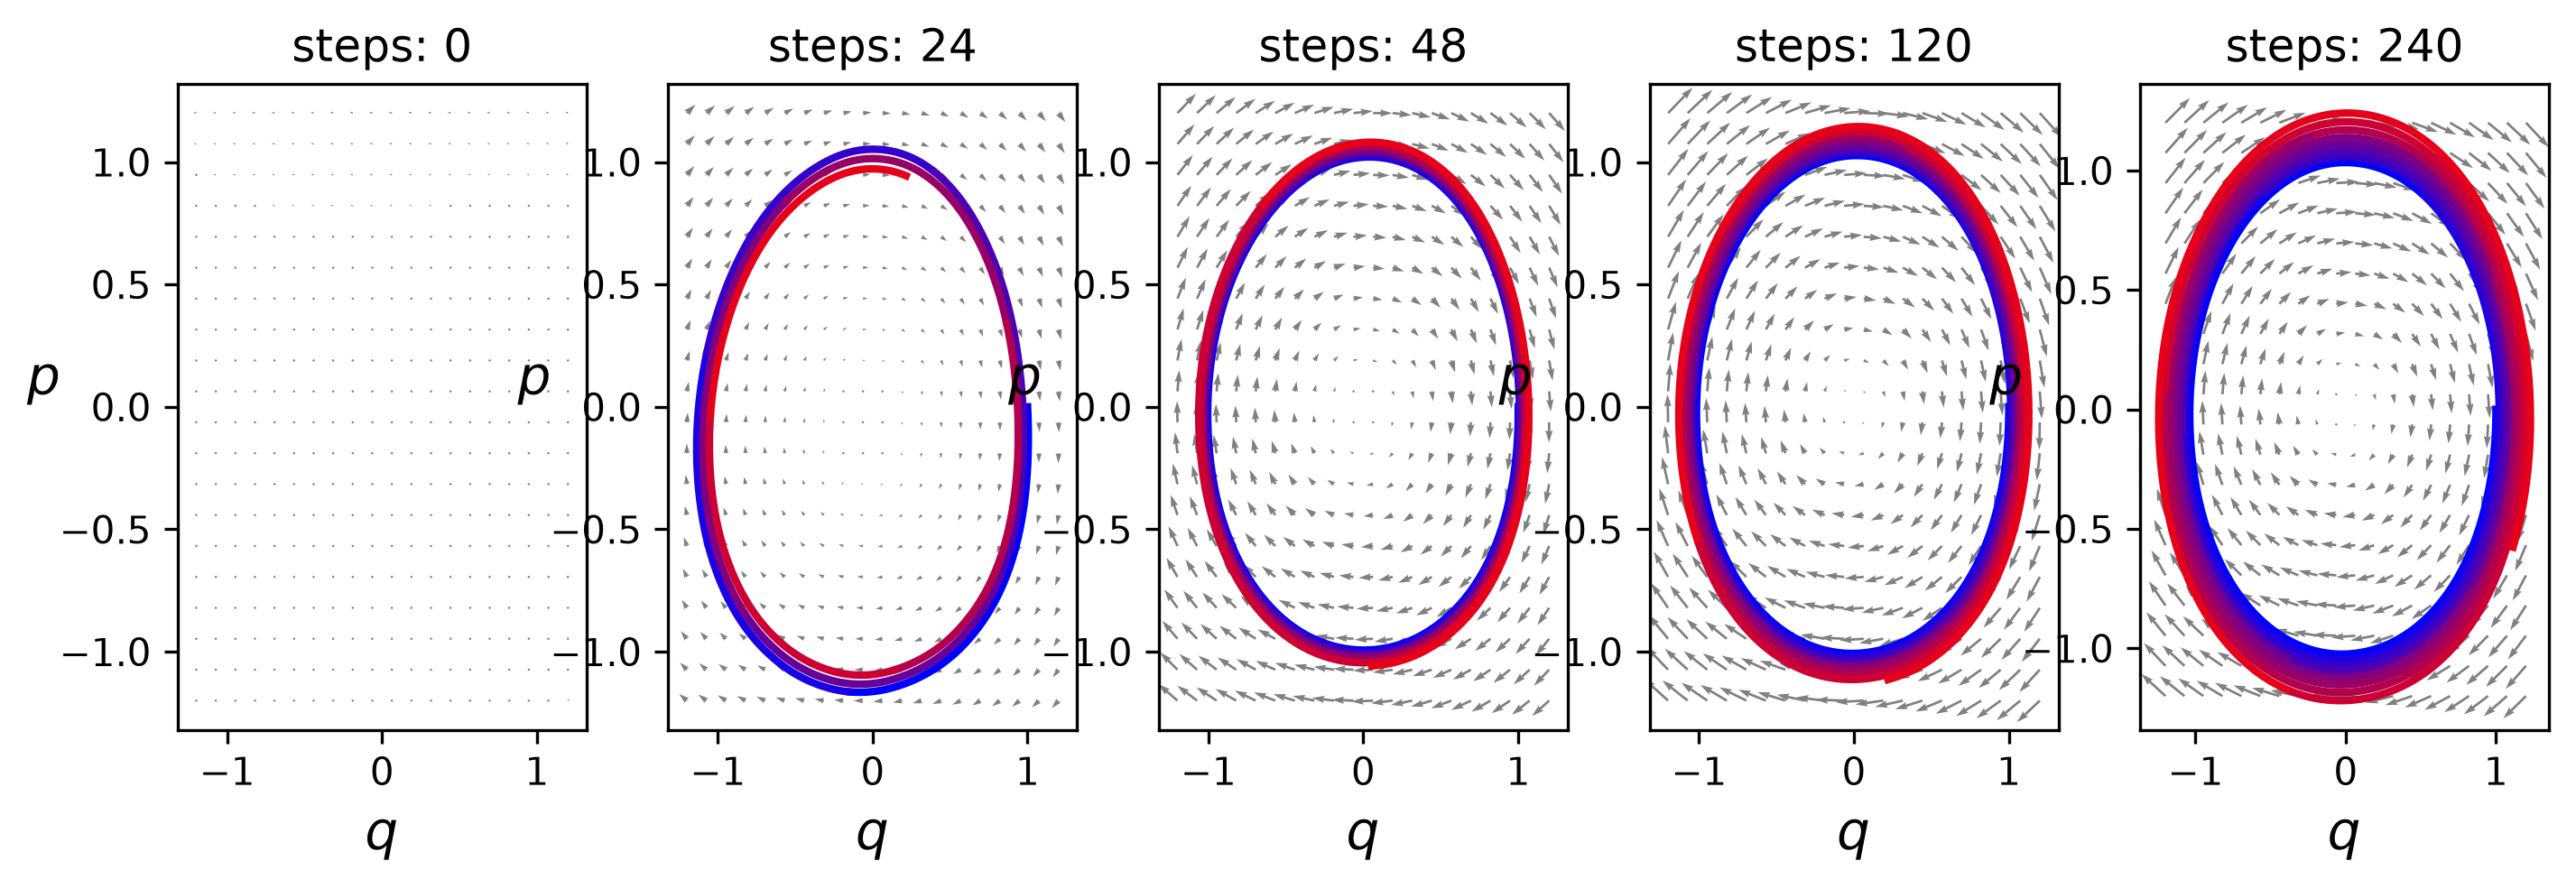

In [112]:
fig = plt.figure(figsize=(11.3, 3.1), facecolor='white', dpi=300)

fig.add_subplot(1, 5, 1, frameon=True)
pred_field = prediction_history[history[0]]
plt.quiver(field['x'][:,0], field['x'][:,1], pred_field[:,0], pred_field[:,1],
        cmap='gray_r', scale=ARROW_SCALE, width=ARROW_WIDTH, color=(.5,.5,.5))

# ivp = base_ivp_history[history[0]]
# for i, l in enumerate(np.split(ivp.T, LINE_SEGMENTS)):
#         color = (float(i)/LINE_SEGMENTS, 0, 1-float(i)/LINE_SEGMENTS)
#         plt.plot(l[:,0],l[:,1],color=color, linewidth=LINE_WIDTH)
    
plt.xlabel("$q$", fontsize=14)
plt.ylabel("$p$", rotation=0, fontsize=14)
#plt.title("Baseline NN", pad=10)
plt.title(f"steps: {step_history[history[0]]}")

###########################


fig.add_subplot(1, 5, 2, frameon=True)
pred_field = prediction_history[history[1]]
plt.quiver(field['x'][:,0], field['x'][:,1], pred_field[:,0], pred_field[:,1],
        cmap='gray_r', scale=ARROW_SCALE, width=ARROW_WIDTH, color=(.5,.5,.5))

ivp = base_ivp_history[history[1]]
for i, l in enumerate(np.split(ivp.T, LINE_SEGMENTS)):
        color = (float(i)/LINE_SEGMENTS, 0, 1-float(i)/LINE_SEGMENTS)
        plt.plot(l[:,0],l[:,1],color=color, linewidth=LINE_WIDTH)
    
plt.xlabel("$q$", fontsize=14)
plt.ylabel("$p$", rotation=0, fontsize=14)
plt.title(f"steps: {step_history[history[1]]}")
###########################


fig.add_subplot(1, 5, 3, frameon=True)
pred_field = prediction_history[history[2]]
plt.quiver(field['x'][:,0], field['x'][:,1], pred_field[:,0], pred_field[:,1],
        cmap='gray_r', scale=ARROW_SCALE, width=ARROW_WIDTH, color=(.5,.5,.5))

ivp = base_ivp_history[history[2]]
for i, l in enumerate(np.split(ivp.T, LINE_SEGMENTS)):
        color = (float(i)/LINE_SEGMENTS, 0, 1-float(i)/LINE_SEGMENTS)
        plt.plot(l[:,0],l[:,1],color=color, linewidth=LINE_WIDTH)
    
plt.xlabel("$q$", fontsize=14)
plt.ylabel("$p$", rotation=0, fontsize=14)
plt.title(f"steps: {step_history[history[2]]}")
###########################


fig.add_subplot(1, 5, 4, frameon=True)
pred_field = prediction_history[history[3]]
plt.quiver(field['x'][:,0], field['x'][:,1], pred_field[:,0], pred_field[:,1],
        cmap='gray_r', scale=ARROW_SCALE, width=ARROW_WIDTH, color=(.5,.5,.5))

ivp = base_ivp_history[history[3]]
for i, l in enumerate(np.split(ivp.T, LINE_SEGMENTS)):
        color = (float(i)/LINE_SEGMENTS, 0, 1-float(i)/LINE_SEGMENTS)
        plt.plot(l[:,0],l[:,1],color=color, linewidth=LINE_WIDTH)
    
plt.xlabel("$q$", fontsize=14)
plt.ylabel("$p$", rotation=0, fontsize=14)
plt.title(f"steps: {step_history[history[3]]}")
###########################


fig.add_subplot(1, 5, 5, frameon=True)
pred_field = prediction_history[history[4]]
plt.quiver(field['x'][:,0], field['x'][:,1], pred_field[:,0], pred_field[:,1],
        cmap='gray_r', scale=ARROW_SCALE, width=ARROW_WIDTH, color=(.5,.5,.5))

ivp = base_ivp_history[history[4]]
for i, l in enumerate(np.split(ivp.T, LINE_SEGMENTS)):
        color = (float(i)/LINE_SEGMENTS, 0, 1-float(i)/LINE_SEGMENTS)
        plt.plot(l[:,0],l[:,1],color=color, linewidth=LINE_WIDTH)
    
plt.xlabel("$q$", fontsize=14)
plt.ylabel("$p$", rotation=0, fontsize=14)
plt.title(f"steps: {step_history[history[4]]}")

In [116]:
layer = nn.Linear(2, 2)
nn.init.orthogonal_(layer.weight)
print(layer.weight)

Parameter containing:
tensor([[ 0.8074, -0.5900],
        [ 0.5900,  0.8074]], requires_grad=True)


In [117]:
print(layer.weight)
print(torch.linalg.eig(layer.weight))
print(torch.abs(torch.linalg.eig(layer.weight)[0]))

Parameter containing:
tensor([[ 0.8074, -0.5900],
        [ 0.5900,  0.8074]], requires_grad=True)
torch.return_types.linalg_eig(
eigenvalues=tensor([0.8074+0.5900j, 0.8074-0.5900j], grad_fn=<LinalgEigBackward0>),
eigenvectors=tensor([[-7.0711e-01+0.0000j, -7.0711e-01-0.0000j],
        [-1.0175e-07+0.7071j, -1.0175e-07-0.7071j]],
       grad_fn=<LinalgEigBackward0>))
tensor([1., 1.], grad_fn=<AbsBackward0>)


In [121]:
a = torch.tensor([[2, 3], [4, 5]])
b = torch.tensor([[0, 1], [-1, 0]])
a @ b

tensor([[-3,  2],
        [-5,  4]])

In [125]:
def my_L2_loss(u, v):
    return (u-v).pow(2).mean()

a = torch.tensor([[3, 6], [9, 12]], dtype=torch.float32)
b = torch.tensor([[3, 5], [6, 6]], dtype=torch.float32)

loss_fn = nn.MSELoss()
print(f"mseloss: {loss_fn(a, b):6f}")

print(f"l2_loss: {my_L2_loss(a, b):.6f}")

mseloss: 11.500000
l2_loss: 11.500000


In [127]:
identity_matrix = torch.tensor([[1, 0, 0], [0, 1, 0], [0, 0, 1]], dtype=torch.int16)
some_vector = torch.tensor([6, 5, 4], dtype=torch.int16)
some_vector @ identity_matrix

tensor([6, 5, 4], dtype=torch.int16)

In [130]:
torch.eye(4).T

tensor([[1., 0., 0., 0.],
        [0., 1., 0., 0.],
        [0., 0., 1., 0.],
        [0., 0., 0., 1.]])